# Tome 2, Appendix D: Inner Products and Projections (Python companion)

Exercises first, solutions at the end. We watch Gram–Schmidt lose orthogonality in floating point and see how to repair it, recover a planet's orbit from noisy observations as Gauss did, test the Gauss–Markov theorem by simulation, compute Hilbert determinants exactly, build orthogonal polynomials and Gauss quadrature rules from a Jacobi matrix, and check Müntz's distance formula. We use `numpy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(4)

## Exercises

**P4.1 (★★) Gram–Schmidt in floating point.** Implement classical Gram–Schmidt (the formula of Theorem 4.5, all projections computed from the original $v_j$) and *modified* Gram–Schmidt (subtract the projections one at a time from the running vector). Apply both, and `numpy.linalg.qr` (Householder reflections, Exercise 4.13), to the $12\times12$ Hilbert matrix and to a $60\times12$ Vandermonde matrix, and measure the loss of orthogonality $\|Q^{\mathsf T}Q-I\|$. Then try classical Gram–Schmidt twice in a row.

**P4.2 (★★) Finding Ceres again.** Generate $40$ noisy observations of points on an ellipse (an orbit seen face on, with the Sun at the origin). Recover the ellipse by least squares, fitting a conic $ax^2+bxy+cy^2+dx+ey=1$ (Theorem 4.8), and plot the data, the true orbit and the fitted one. Compare `numpy.linalg.lstsq`, the normal equations and $QR$. Then repeat with observations covering only a third of the orbit: is the fitted conic still an ellipse?

**P4.3 (★) Gauss–Markov by simulation.** For a straight-line model $y=\beta_0+\beta_1x+\varepsilon$ with $20$ points and independent noise, compare the variance of the least squares slope with that of two other unbiased linear estimators: the slope through the two extreme points, and the slope between the means of the left and right halves. Check the ordering predicted by Theorem 4.10. Then use heavy-tailed noise (Student $t$ with $2$ degrees of freedom): what does the theorem still promise?

**P4.4 (★) The Hilbert matrix.** Compute $\det H_n$ exactly with fractions for $n\le10$, compare with Corollary 4.13 and with the integers of Exercise 4.7, and compare with `numpy.linalg.det`. Solve $H_nx=H_n\mathbf 1$ in floating point for $n=4,8,12,16$: how many digits of $x=\mathbf 1$ survive? Relate this to the condition number.

**P4.5 (★★★) Orthogonal polynomials and Gauss rules from scratch.** For a weight $w$ on $[-1,1]$, compute the recurrence coefficients $\alpha_n,\beta_n$ of Theorem 4.15 by the *Stieltjes procedure* (run the recurrence, computing each $\alpha_n,\beta_n$ by numerical integration on a fine grid), build the Jacobi matrix of Proposition 4.17, and get the Gauss nodes as its eigenvalues and the weights as $\lambda_i=\bigl(\int w\bigr)\,q_{i,1}^2$, where $q_i$ is the unit eigenvector (Golub–Welsch). Check against `numpy.polynomial.legendre.leggauss` for $w=1$, check exactness up to degree $2n-1$ and failure at $2n$ (Theorem 4.18), and do the same for $w(t)=\sqrt{1-t^2}$.

**P4.6 (★★) Müntz's formula.** For $m=1$, compute the distance in $L^2[0,1]$ from $t$ to $\operatorname{span}(t^{a_1},\dots,t^{a_N})$ exactly from Gram determinants with rational exponents, compare with the product formula of Exercise 4.14, and plot $d_N$ for $a_k=k+\frac12$ and for $a_k=k^2+\frac12$. Which one goes to $0$?

## Solutions

### P4.1
**How to find it.** In exact arithmetic the two versions agree. In floating point, classical Gram–Schmidt computes $\langle v_j,e_i\rangle$ with the original $v_j$ against $e_i$ that are already slightly non-orthogonal, and errors grow like the square of the condition number; modified Gram–Schmidt projects the *current* residual, and the error grows only like the condition number. Householder is orthogonal by construction. Running classical Gram–Schmidt twice ("twice is enough", Kahan and Parlett) repairs it, provided the matrix is not numerically singular: fine for the Vandermonde matrix, hopeless for $H_{12}$, whose condition number is about $10^{16}$, the reciprocal of machine precision.

In [2]:
def cgs(A):
    m, n = A.shape; Q = np.zeros((m, n))
    for j in range(n):
        u = A[:, j] - Q[:, :j] @ (Q[:, :j].T @ A[:, j])
        Q[:, j] = u / np.linalg.norm(u)
    return Q

def mgs(A):
    Q = A.astype(float).copy(); n = A.shape[1]
    for j in range(n):
        Q[:, j] /= np.linalg.norm(Q[:, j])
        Q[:, j + 1:] -= np.outer(Q[:, j], Q[:, j] @ Q[:, j + 1:])
    return Q

hilb = lambda n: 1.0 / (np.arange(n)[:, None] + np.arange(n)[None, :] + 1)
vand = np.vander(np.linspace(0, 1, 60), 12, increasing=True)
loss = lambda Q: np.linalg.norm(Q.T @ Q - np.eye(Q.shape[1]))
for name, A in [("Hilbert 12x12", hilb(12)), ("Vandermonde 60x12", vand)]:
    print(f"{name}: cond = {np.linalg.cond(A):.1e}")
    for meth, Q in [("classical", cgs(A)), ("modified", mgs(A)), ("Householder", np.linalg.qr(A)[0]),
                    ("classical twice", cgs(cgs(A)))]:
        print(f"   {meth:16s} ||Q^T Q - I|| = {loss(Q):.1e}")

Hilbert 12x12: cond = 1.6e+16
   classical        ||Q^T Q - I|| = 5.5e+00
   modified         ||Q^T Q - I|| = 1.3e-01
   Householder      ||Q^T Q - I|| = 1.7e-15
   classical twice  ||Q^T Q - I|| = 1.4e+00
Vandermonde 60x12: cond = 1.2e+08
   classical        ||Q^T Q - I|| = 2.4e+00
   modified         ||Q^T Q - I|| = 3.1e-09
   Householder      ||Q^T Q - I|| = 2.1e-15
   classical twice  ||Q^T Q - I|| = 4.2e-13


Classical Gram–Schmidt returns "orthonormal" vectors at angles far from $90°$; the mathematics of Theorem 4.5 is exact, the arithmetic is not. Tome C5 explains the error analysis.

### P4.2
**How to find it.** A conic not through the origin can be written $ax^2+bxy+cy^2+dx+ey=1$: five unknowns, linear in the data, so each observation gives one linear equation and $40$ observations give an overdetermined system. Solve it by least squares, then plot the zero set of the fitted quadratic with `contour`.

long arc: lstsq = [ 0.1546 -0.0136  0.1549  0.217   0.1344], normal eqs and QR agree: True, b^2-4ac = -0.0957 (ellipse)
short arc: lstsq = [ 0.0646  0.0753 -0.0372 -0.0572  0.5558], normal eqs and QR agree: True, b^2-4ac = 0.0153 (hyperbola)


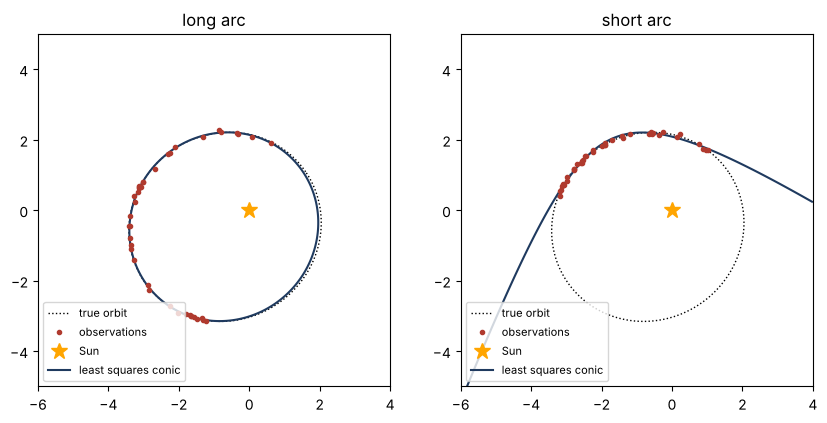

In [3]:
a_true, e_true, rot = 2.77, 0.30, 0.6          # semi-major axis, eccentricity, orientation (Ceres-like shape)
b_true = a_true * math.sqrt(1 - e_true**2)
def orbit(t):
    x, y = a_true * np.cos(t) - a_true * e_true, b_true * np.sin(t)   # focus (Sun) at the origin
    return x * math.cos(rot) - y * math.sin(rot), x * math.sin(rot) + y * math.cos(rot)

def fit(t_lo, t_hi, noise=0.03, n=40):
    t_obs = np.sort(rng.uniform(t_lo, t_hi, n))
    X, Y = orbit(t_obs); X = X + noise * rng.standard_normal(n); Y = Y + noise * rng.standard_normal(n)
    M = np.column_stack([X**2, X * Y, Y**2, X, Y]); b = np.ones(n)
    return X, Y, M, b

gx, gy = np.meshgrid(np.linspace(-6, 4, 400), np.linspace(-5, 5, 400))
tt = np.linspace(0, 2 * np.pi, 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (lo, hi, title) in zip(axes, [(0.2, 4.0, "long arc"), (0.2, 2.2, "short arc")]):
    X, Y, M, b = fit(lo, hi)
    p1 = np.linalg.lstsq(M, b, rcond=None)[0]
    p2 = np.linalg.solve(M.T @ M, M.T @ b)
    Qm, Rm = np.linalg.qr(M); p3 = np.linalg.solve(Rm, Qm.T @ b)
    disc = p1[1]**2 - 4 * p1[0] * p1[2]
    print(f"{title}: lstsq = {p1.round(4)}, normal eqs and QR agree: {np.allclose(p1, p2) and np.allclose(p1, p3)}, "
          f"b^2-4ac = {disc:.4f} ({'ellipse' if disc < 0 else 'hyperbola'})")
    F = p1[0] * gx**2 + p1[1] * gx * gy + p1[2] * gy**2 + p1[3] * gx + p1[4] * gy - 1
    ax.plot(*orbit(tt), 'k:', lw=1, label='true orbit')
    ax.contour(gx, gy, F, [0], colors='#1f3a5f')
    ax.plot(X, Y, '.', color='#b03a2e', label='observations'); ax.plot(0, 0, '*', color='orange', ms=12, label='Sun')
    ax.plot([], [], color='#1f3a5f', label='least squares conic'); ax.set_aspect('equal'); ax.set_title(title)
    ax.legend(fontsize=8, loc='lower left')
plt.show()

With a long arc, the fitted conic is the orbit. With a short arc (a third of the orbit, noise of about one percent), least squares happily returns a *hyperbola* that fits the data just as well: five free coefficients are too many for a short, noisy arc, and the problem is ill-conditioned. Piazzi's six weeks covered only about three degrees of sky, far less than this. Gauss succeeded because he did not fit a general conic: he used Kepler's laws (the Sun is a focus, and the speed along the orbit is fixed by the law of areas), which leave far fewer unknowns, and least squares only polished the result. Constraints from the physics are worth more than data.

### P4.3
**How to find it.** All three estimators are linear in $y$ and unbiased (each is exact on noiseless lines), so the theorem applies; the variance of an estimator $c^{\mathsf T}y$ is $\sigma^2\|c\|^2$, which we can also compute exactly and compare with the simulation.

In [4]:
x = np.linspace(0, 1, 20); A = np.column_stack([np.ones(20), x])
c_ls = np.linalg.solve(A.T @ A, A.T)[1]                       # least squares slope
c_ext = np.zeros(20); c_ext[0], c_ext[-1] = -1 / (x[-1] - x[0]), 1 / (x[-1] - x[0])
L, Rh = slice(0, 10), slice(10, 20)
c_half = np.zeros(20); d = x[Rh].mean() - x[L].mean(); c_half[L] = -1 / (10 * d); c_half[Rh] = 1 / (10 * d)
for c in (c_ls, c_ext, c_half): assert np.allclose(c @ A, [0, 1])   # unbiased: c^T A = (0, 1)

def simulate(noise, trials=20000):
    Y = 1 + 2 * x + noise((trials, 20))
    return [np.var(Y @ c) for c in (c_ls, c_ext, c_half)]
print("exact variances (sigma=1):", [round(float(c @ c), 3) for c in (c_ls, c_ext, c_half)])
print("Gaussian noise          :", np.round(simulate(lambda s: rng.standard_normal(s)), 3))
tv = simulate(lambda s: rng.standard_t(2, s))
print("Student t(2) noise      :", np.round(tv, 1), " (infinite true variance: the sample values are unstable)")

exact variances (sigma=1): [0.543, 2.0, 0.722]
Gaussian noise          : [0.538 2.01  0.713]
Student t(2) noise      : [ 4.9 16.9  7.1]  (infinite true variance: the sample values are unstable)


The order least squares < halves < extremes holds as predicted. With $t_2$ noise the variance is infinite and Gauss–Markov promises nothing; robust methods (least absolute deviations, Huber) take over. The theorem needs its hypotheses.

### P4.4
**How to find it.** Fractions make the determinant exact. For the linear system, the relative error is at most about $\kappa(H_n)\cdot10^{-16}$, so the number of correct digits is about $16-\log_{10}\kappa$.

In [5]:
def det_exact(M):
    M = [row[:] for row in M]; n = len(M); d = Fraction(1)
    for j in range(n):
        p = next(i for i in range(j, n) if M[i][j] != 0)
        if p != j: M[j], M[p] = M[p], M[j]; d = -d
        d *= M[j][j]
        for i in range(j + 1, n):
            f = M[i][j] / M[j][j]
            M[i] = [a - f * b for a, b in zip(M[i], M[j])]
    return d

c = lambda n: math.prod(math.factorial(k) for k in range(1, n))
prod_formula = lambda n: math.prod((2 * k + 1) * math.comb(2 * k, k)**2 for k in range(1, n))
for n in range(1, 11):
    H = [[Fraction(1, i + j + 1) for j in range(n)] for i in range(n)]
    d = det_exact(H)
    assert d == Fraction(c(n)**4, c(2 * n)) and d == Fraction(1, prod_formula(n))
    print(f"n={n:2d}  1/det H_n = {1/d}   numpy det = {np.linalg.det(hilb(n)):.3e}   exact = {float(d):.3e}")
for n in (4, 8, 12, 16):
    H = hilb(n); xs = np.linalg.solve(H, H @ np.ones(n))
    print(f"n={n:2d}  cond = {np.linalg.cond(H):.1e}   max error in x = {np.abs(xs - 1).max():.1e}")

n= 1  1/det H_n = 1   numpy det = 1.000e+00   exact = 1.000e+00
n= 2  1/det H_n = 12   numpy det = 8.333e-02   exact = 8.333e-02
n= 3  1/det H_n = 2160   numpy det = 4.630e-04   exact = 4.630e-04
n= 4  1/det H_n = 6048000   numpy det = 1.653e-07   exact = 1.653e-07
n= 5  1/det H_n = 266716800000   numpy det = 3.749e-12   exact = 3.749e-12
n= 6  1/det H_n = 186313420339200000   numpy det = 5.367e-18   exact = 5.367e-18
n= 7  1/det H_n = 2067909047925770649600000   numpy det = 4.836e-25   exact = 4.836e-25
n= 8  1/det H_n = 365356847125734485878112256000000   numpy det = 2.737e-33   exact = 2.737e-33
n= 9  1/det H_n = 1028781784378569697887052962909388800000000   numpy det = 9.720e-43   exact = 9.720e-43
n=10  1/det H_n = 46206893947914691316295628839036278726983680000000000   numpy det = 2.164e-53   exact = 2.164e-53
n= 4  cond = 1.6e+04   max error in x = 5.4e-14
n= 8  cond = 1.5e+10   max error in x = 1.3e-07
n=12  cond = 1.6e+16   max error in x = 2.8e-01
n=16  cond = 3.1e+17   max e

For $n=16$ the condition number exceeds $10^{16}$ (in floating point we cannot even compute it reliably) and no digit survives, although the exact inverse of $H_{16}$ has integer entries.

### P4.5
**How to find it.** Represent polynomials by their values on a fine Gauss–Legendre grid (exact for the polynomial parts, very accurate for smooth weights), so inner products are weighted sums. The Stieltjes procedure is Theorem 4.15 read as an algorithm. For the weights: the unit eigenvector of $J_n$ for the node $t_i$ is proportional to $(\tilde p_0(t_i),\dots,\tilde p_{n-1}(t_i))$ with orthonormal $\tilde p_k$, and $1/\sum_k\tilde p_k(t_i)^2$ is the Gauss weight (Christoffel), which gives Golub and Welsch's formula.

In [6]:
grid, gw = np.polynomial.legendre.leggauss(400)

def stieltjes(w, n):
    W = gw * w(grid); alpha, beta = [], []
    p_prev, p = np.zeros_like(grid), np.ones_like(grid)
    norm_prev = None
    for k in range(n):
        norm = np.sum(W * p * p)
        alpha.append(np.sum(W * grid * p * p) / norm)
        beta.append(norm / norm_prev if k > 0 else np.sum(W))
        p_prev, p = p, (grid - alpha[-1]) * p - (beta[-1] if k > 0 else 0) * p_prev
        norm_prev = norm
    return np.array(alpha), np.array(beta)

def golub_welsch(w, n):
    a, b = stieltjes(w, n)
    J = np.diag(a) + np.diag(np.sqrt(b[1:]), 1) + np.diag(np.sqrt(b[1:]), -1)
    nodes, V = np.linalg.eigh(J)
    return nodes, b[0] * V[0]**2

n = 6
nodes, weights = golub_welsch(lambda t: np.ones_like(t), n)
ref_nodes, ref_weights = np.polynomial.legendre.leggauss(n)
print("nodes match leggauss:", np.allclose(nodes, ref_nodes), "  weights match:", np.allclose(weights, ref_weights))
for deg in (2 * n - 2, 2 * n - 1, 2 * n):             # f(t) = (t + 0.3)^deg, no symmetry to help
    exact = (1.3**(deg + 1) - (-0.7)**(deg + 1)) / (deg + 1)
    print(f"degree {deg:2d}: rule = {np.sum(weights * (nodes + 0.3)**deg):.12f}   exact = {exact:.12f}")

nodes2, weights2 = golub_welsch(lambda t: np.sqrt(1 - t**2), n)
k = np.arange(1, n + 1)
print("w = sqrt(1-t^2): nodes =", nodes2.round(6))
print("                 cos(k pi/(n+1)) =", np.sort(np.cos(k * np.pi / (n + 1))).round(6))

nodes match leggauss: True   weights match: True
degree 10: rule = 1.631034291618   exact = 1.631034291618
degree 11: rule = 1.940353652940   exact = 1.940353652940
degree 12: rule = 2.329815733667   exact = 2.330553812328
w = sqrt(1-t^2): nodes = [-0.900969 -0.62349  -0.222521  0.222521  0.62349   0.900969]
                 cos(k pi/(n+1)) = [-0.900969 -0.62349  -0.222521  0.222521  0.62349   0.900969]


The weight $\sqrt{1-t^2}$ gives the Chebyshev polynomials of the second kind, $U_n(\cos\theta)=\frac{\sin(n+1)\theta}{\sin\theta}$, whose zeros are $\cos\frac{k\pi}{n+1}$: the Stieltjes procedure found them with no formula.

### P4.6
**How to find it.** With rational exponents, $\langle t^a,t^b\rangle=\frac1{a+b+1}$ is rational and Gram determinants are exact fractions; Theorem 4.11(b) gives $d_N^2$ as a ratio.

exact Gram ratios agree with the product formula for N = 1..8


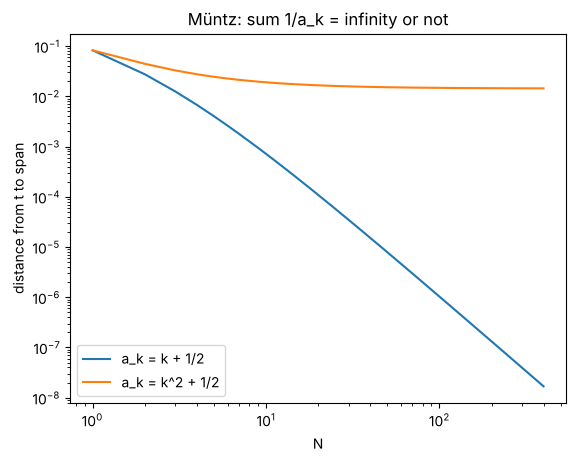

In [7]:
def gram_det(exps):
    return det_exact([[1 / (a + b + 1) for b in exps] for a in exps])

def d2_exact(m, exps):
    return gram_det(exps + [Fraction(m)]) / gram_det(exps)

def d2_formula(m, exps):
    return Fraction(1, 2 * m + 1) * math.prod(((a - m) / (a + m + 1))**2 for a in exps)

ex1 = [Fraction(2 * k + 1, 2) for k in range(1, 9)]
assert all(d2_exact(1, ex1[:N]) == d2_formula(1, ex1[:N]) for N in range(1, 9))
print("exact Gram ratios agree with the product formula for N = 1..8")

Ns = np.arange(1, 400)
for label, a in [("a_k = k + 1/2", lambda k: k + 0.5), ("a_k = k^2 + 1/2", lambda k: k * k + 0.5)]:
    f = np.array([((a(k) - 1) / (a(k) + 2))**2 for k in Ns])
    plt.loglog(Ns, np.sqrt(np.cumprod(f) / 3), label=label)
plt.xlabel("N"); plt.ylabel("distance from t to span"); plt.legend(); plt.title("Müntz: sum 1/a_k = infinity or not")
plt.show()

For $a_k=k+\frac12$, $\sum1/a_k=\infty$ and the distance decays like a power of $N$; for $a_k=k^2+\frac12$ the series converges, and the distance levels off at a positive value: $t$ is never approximated. Müntz's theorem in one picture.